# Data Mining Lab Assignment — Book Recommender System on a Medallion Data Lake

**Name:** Kritika Yadav  
**Enrolment No.:** LCB2023006  

---

## What this notebook does

It takes the raw, messy **Book-Crossing** dataset through a **Bronze → Silver → Gold**
(medallion) pipeline and then uses the Gold layer to build a working
**item-based collaborative-filtering** recommender that suggests books to a user.

| Layer | Meaning | What lives here |
|---|---|---|
| **Bronze** | Raw landing zone | Byte-faithful copy of the 3 source files + `ingestion_timestamp`. No cleaning. |
| **Silver** | Cleaned & conformed | De-duplicated, validated, enriched tables with referential integrity. |
| **Gold** | Model-ready | Sparse user×book rating matrix, book lookup, user/book aggregates. |

Each layer is written to disk as **Parquet** (columnar, compressed, schema-carrying), so every
step is reproducible and the layers below it are never mutated.

### Notebook map

| Step | Section |
|---|---|
| 0 | Environment, folders, dataset download |
| 1 | Bronze layer — raw ingestion |
| 2 | Bronze EDA — what is wrong with this data |
| 3 | Silver layer — cleaning rules |
| 4 | Gold layer — model-ready artefacts |
| 5 | Item-based collaborative-filtering recommender |
| 6 | Demo and sanity checks |

---
# Step 0 — Environment and Data Lake Folders

We create the three layer folders and fetch the raw zip. The notebook is written to run
unchanged in **Google Colab**; if the three CSVs are already beside the notebook it reuses
them instead of re-downloading.

In [1]:
import os, io, sys, zipfile, urllib.request, warnings, difflib
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("pandas      ", pd.__version__)
print("numpy       ", np.__version__)
import sklearn; print("scikit-learn", sklearn.__version__)

pandas       3.1.1
numpy        2.5.5


scikit-learn 1.9.1


In [2]:
# ---- the data lake -------------------------------------------------------
LAKE   = "datalake"
BRONZE = os.path.join(LAKE, "bronze")
SILVER = os.path.join(LAKE, "silver")
GOLD   = os.path.join(LAKE, "gold")
RAW    = os.path.join(LAKE, "raw")

for d in (BRONZE, SILVER, GOLD, RAW):
    os.makedirs(d, exist_ok=True)

print("Data lake layout")
for d in (RAW, BRONZE, SILVER, GOLD):
    print("  ", d)

Data lake layout
   datalake/raw
   datalake/bronze
   datalake/silver
   datalake/gold


In [3]:
# ---- fetch the raw Book-Crossing files -----------------------------------
DATA_URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
FILES    = ["BX-Users.csv", "BX-Books.csv", "BX-Book-Ratings.csv"]

def locate_raw():
    """Return {logical_name: path}. Reuse local copies, else download the zip."""
    found = {}
    for f in FILES:
        for cand in (os.path.join(RAW, f), f, os.path.join("data", f)):
            if os.path.exists(cand):
                found[f] = cand
                break
    if len(found) == 3:
        return found

    print("Downloading", DATA_URL)
    blob = urllib.request.urlopen(DATA_URL).read()
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        z.extractall(RAW)
    return {f: os.path.join(RAW, f) for f in FILES}

RAW_PATHS = locate_raw()
for k, v in RAW_PATHS.items():
    print(f"{k:22s} {os.path.getsize(v)/1e6:8.2f} MB   {v}")

BX-Users.csv              12.28 MB   datalake/raw/BX-Users.csv
BX-Books.csv              77.79 MB   datalake/raw/BX-Books.csv
BX-Book-Ratings.csv       30.68 MB   datalake/raw/BX-Book-Ratings.csv


---
# Step 1 — Build the Bronze Layer

**Rule for Bronze: ingest, do not improve.** Bronze is the untouched copy of the source, so a
mistake made later can always be replayed from here.

Two things about these files force our hand on *how* we read them:

| Problem in the source | Why it breaks a naive `read_csv` | What we do |
|---|---|---|
| Fields separated by `;`, not `,` | Everything lands in one column | `sep=";"` |
| Not UTF-8 (it is Latin-1 / CP-1252) | `UnicodeDecodeError` | `encoding="latin-1"` |
| A few `BX-Books.csv` rows have an unescaped `"` inside a title, so the row has extra fields | `ParserError`, read aborts | `on_bad_lines="skip"` and we **count and report** the skipped rows |
| `"NULL"` strings, numbers stored as text | Silent wrong dtypes | read **everything as `str`**, cast in Silver |

Reading every column as text is deliberate: a dtype guess *is* a cleaning decision, and cleaning
decisions belong in Silver. The only column we add is `ingestion_timestamp`, the lineage stamp
that says when this snapshot entered the lake.

In [4]:
INGESTED_AT = datetime.now(timezone.utc).replace(microsecond=0)

def read_raw(path):
    """Read a Book-Crossing CSV as-is: all text, nothing coerced, nothing dropped but
    structurally broken lines (which we count)."""
    total_lines = sum(1 for _ in open(path, "rb")) - 1       # minus header
    df = pd.read_csv(
        path,
        sep=";",
        encoding="latin-1",      # non-UTF-8 source
        dtype=str,               # no dtype guessing in Bronze
        quotechar='"',
        on_bad_lines="skip",     # a handful of rows have an unescaped quote
        low_memory=False,
        keep_default_na=False,   # keep the literal string "NULL" visible
        na_values=[],
    )
    return df, total_lines, total_lines - len(df)

bronze = {}
report = []

for logical, path in RAW_PATHS.items():
    name = {"BX-Users.csv": "users",
            "BX-Books.csv": "books",
            "BX-Book-Ratings.csv": "ratings"}[logical]

    df, lines, skipped = read_raw(path)
    df["ingestion_timestamp"] = INGESTED_AT
    bronze[name] = df

    out = os.path.join(BRONZE, f"{name}.parquet")
    df.to_parquet(out, index=False, compression="snappy")

    report.append({
        "table": name,
        "source_file": logical,
        "source_rows": lines,
        "rows_ingested": len(df),
        "malformed_skipped": skipped,
        "columns": df.shape[1],
        "parquet_MB": round(os.path.getsize(out) / 1e6, 2),
    })

bronze_report = pd.DataFrame(report)
display(bronze_report)
print("\ningestion_timestamp (UTC):", INGESTED_AT)

,table,source_file,source_rows,rows_ingested,malformed_skipped,columns,parquet_MB
0,users,BX-Users.csv,278859,278858,1,4,4.54
1,books,BX-Books.csv,271379,271360,19,9,21.65
2,ratings,BX-Book-Ratings.csv,1149780,1149780,0,4,9.84



ingestion_timestamp (UTC): 2026-11-26 18:30:35+00:00


In [5]:
for name, df in bronze.items():
    print(f"=== bronze/{name}  {df.shape[0]:,} rows x {df.shape[1]} cols ".ljust(72, "="))
    display(df.head(3))

=== bronze/users  278,858 rows x 4 cols ================================


,User-ID,Location,Age,ingestion_timestamp
0,1,"nyc, new york, usa",NULL,2026-11-26 18:30:35+00:00
1,2,"stockton, california, usa",18,2026-11-26 18:30:35+00:00
2,3,"moscow, yukon territory, russia",NULL,2026-11-26 18:30:35+00:00


=== bronze/books  271,360 rows x 9 cols ================================


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,2026-11-26 18:30:35+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,2026-11-26 18:30:35+00:00
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,2026-11-26 18:30:35+00:00


=== bronze/ratings  1,149,780 rows x 4 cols ============================


,User-ID,ISBN,Book-Rating,ingestion_timestamp
0,276725,034545104X,0,2026-11-26 18:30:35+00:00
1,276726,0155061224,5,2026-11-26 18:30:35+00:00
2,276727,0446520802,0,2026-11-26 18:30:35+00:00


**Bronze is done.** Three Parquet files, all columns still text, one lineage column added, and a
written record of exactly how many source lines were malformed. Nothing has been corrected.

---
# Step 2 — Explore the Bronze Data (EDA)

We read the Bronze tables **back from Parquet** (not from the variables above) so the EDA proves
the layer round-trips. For every item the assignment lists, we state the finding and the Silver
action it triggers.

In [6]:
b_users   = pd.read_parquet(os.path.join(BRONZE, "users.parquet"))
b_books   = pd.read_parquet(os.path.join(BRONZE, "books.parquet"))
b_ratings = pd.read_parquet(os.path.join(BRONZE, "ratings.parquet"))

print("read back from bronze/:",
      f"users={b_users.shape}", f"books={b_books.shape}", f"ratings={b_ratings.shape}")

read back from bronze/: users=(278858, 4) books=(271360, 9) ratings=(1149780, 4)


## 2.1 Shape, data types and missing values

In [7]:
def profile(df, label):
    """One row per column: dtype, nulls, empty/NULL-string count, distinct values."""
    rows = []
    for c in df.columns:
        s = df[c]
        as_txt = s.astype(str).str.strip()
        rows.append({
            "table": label,
            "column": c,
            "dtype": str(s.dtype),
            "null_count": int(s.isna().sum()),
            "blank_or_NULL": int(as_txt.isin(["", "NULL", "nan", "None"]).sum()),
            "n_distinct": int(s.nunique(dropna=True)),
            "example": next((v for v in as_txt if v not in ("", "NULL")), ""),
        })
    return pd.DataFrame(rows)

prof = pd.concat([profile(b_users, "users"),
                  profile(b_books, "books"),
                  profile(b_ratings, "ratings")], ignore_index=True)
prof["example"] = prof["example"].str.slice(0, 40)
display(prof)

,table,column,dtype,null_count,blank_or_NULL,n_distinct,example
0,users,User-ID,str,0,0,278858,1
1,users,Location,str,0,0,57339,"nyc, new york, usa"
2,users,Age,str,0,110762,166,18
3,users,ingestion_timestamp,"datetime64[us, UTC]",0,0,1,2026-11-26 18:30:35+00:00
4,books,ISBN,str,0,0,271360,0195153448
5,books,Book-Title,str,0,0,242135,Classical Mythology
6,books,Book-Author,str,0,1,102024,Mark P. O. Morford
7,books,Year-Of-Publication,str,0,0,118,2002
8,books,Publisher,str,0,0,16808,Oxford University Press
9,books,Image-URL-S,str,0,0,271044,http://images.amazon.com/images/P/019515


In [8]:
# duplicate rows per table, and duplicate keys
dups = pd.DataFrame([
    {"table": "users",   "exact_duplicate_rows": int(b_users.drop(columns=["ingestion_timestamp"]).duplicated().sum()),
     "duplicate_keys": int(b_users["User-ID"].duplicated().sum()), "key": "User-ID"},
    {"table": "books",   "exact_duplicate_rows": int(b_books.drop(columns=["ingestion_timestamp"]).duplicated().sum()),
     "duplicate_keys": int(b_books["ISBN"].duplicated().sum()), "key": "ISBN"},
    {"table": "ratings", "exact_duplicate_rows": int(b_ratings.drop(columns=["ingestion_timestamp"]).duplicated().sum()),
     "duplicate_keys": int(b_ratings.duplicated(subset=["User-ID", "ISBN"]).sum()), "key": "(User-ID, ISBN)"},
])
display(dups)

,table,exact_duplicate_rows,duplicate_keys,key
0,users,0,0,User-ID
1,books,0,0,ISBN
2,ratings,0,0,"(User-ID, ISBN)"


**Finding.** Every column arrived as `object` (text) because Bronze refuses to guess dtypes, so
`Age`, `Book-Rating` and `Year-Of-Publication` are strings and cannot be compared numerically
yet. `Age` is overwhelmingly the literal string `"NULL"` rather than a real missing value, and
`Location` is one free-text blob holding three facts. There are no exact duplicate rows and the
primary keys (`User-ID`, `ISBN`) are already unique; `(User-ID, ISBN)` in ratings is unique too.
**In Silver:** cast `Age`/`Book-Rating`/`Year-Of-Publication` to numeric with `errors="coerce"`,
turn `"NULL"`-style strings into true nulls, split `Location`, and still run the de-duplication
step so the pipeline stays correct if a future snapshot does contain duplicates.

## 2.2 Distribution of ratings — how many are 0?

In [9]:
r_num = pd.to_numeric(b_ratings["Book-Rating"], errors="coerce")

dist = (r_num.value_counts().sort_index()
        .rename_axis("rating").reset_index(name="count"))
dist["share_%"] = (100 * dist["count"] / len(r_num)).round(2)
display(dist)

zeros = int((r_num == 0).sum())
print(f"total ratings     : {len(r_num):,}")
print(f"rating == 0       : {zeros:,}  ({100*zeros/len(r_num):.2f}%)   <- implicit, NOT a score")
print(f"explicit 1..10    : {len(r_num)-zeros:,}  ({100*(len(r_num)-zeros)/len(r_num):.2f}%)")
print(f"mean of 1..10 only: {r_num[r_num>0].mean():.2f}")

,rating,count,share_%
0,0,716109,62.28
1,1,1770,0.15
2,2,2759,0.24
3,3,5996,0.52
4,4,8904,0.77
5,5,50974,4.43
6,6,36924,3.21
7,7,76457,6.65
8,8,103736,9.02
9,9,67541,5.87


total ratings     : 1,149,780
rating == 0       : 716,109  (62.28%)   <- implicit, NOT a score
explicit 1..10    : 433,671  (37.72%)
mean of 1..10 only: 7.60


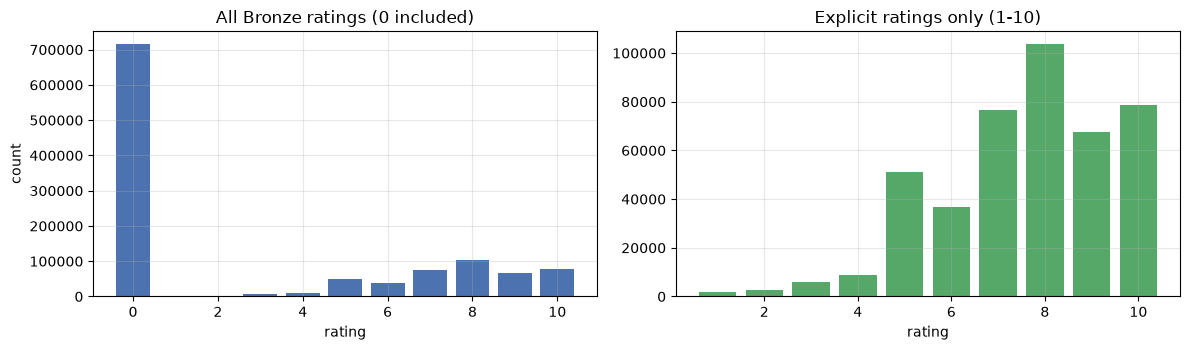

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(dist["rating"], dist["count"], color="#4C72B0")
ax[0].set_title("All Bronze ratings (0 included)"); ax[0].set_xlabel("rating"); ax[0].set_ylabel("count")
e = dist[dist["rating"] > 0]
ax[1].bar(e["rating"], e["count"], color="#55A868")
ax[1].set_title("Explicit ratings only (1-10)"); ax[1].set_xlabel("rating")
plt.tight_layout(); plt.show()

**Finding.** A **0** here does not mean "a terrible book" — in Book-Crossing it is the code for
*interaction without an explicit score*, and it is the **majority of the file** (see the
percentage printed above). Leaving it in would drag every book's mean toward zero and poison the
cosine similarity, because two books would look alike merely for sharing non-raters. Among the
real 1–10 scores the distribution is strongly left-skewed: 7, 8 and 10 dominate, so users mostly
rate books they already liked. **In Silver:** drop all rating-0 rows and keep only 1–10.

## 2.3 Distribution of user ages — impossible values

In [11]:
age = pd.to_numeric(b_users["Age"], errors="coerce")

print(f"users                 : {len(age):,}")
print(f"age missing / 'NULL'  : {age.isna().sum():,}  ({100*age.isna().mean():.1f}%)")
print(f"age present           : {age.notna().sum():,}")
display(age.describe().to_frame("Age").T.round(2))

bad = pd.DataFrame([
    {"bucket": "age < 5  (impossible)",   "count": int((age < 5).sum())},
    {"bucket": "age 5-100 (plausible)",   "count": int(((age >= 5) & (age <= 100)).sum())},
    {"bucket": "age > 100 (impossible)",  "count": int((age > 100).sum())},
    {"bucket": "missing",                 "count": int(age.isna().sum())},
])
bad["share_%"] = (100 * bad["count"] / len(age)).round(2)
display(bad)
print("sample of impossible ages:", sorted(age[(age < 5) | (age > 100)].dropna().unique())[:18], "...")
print("max age in file:", age.max())

users                 : 278,858


age missing / 'NULL'  : 110,762  (39.7%)
age present           : 168,096


,count,mean,std,min,25%,50%,75%,max
Age,168096.0,34.75,14.43,0.0,24.0,32.0,44.0,244.0


,bucket,count,share_%
0,age < 5 (impossible),882,0.32
1,age 5-100 (plausible),166848,59.83
2,age > 100 (impossible),366,0.13
3,missing,110762,39.72


sample of impossible ages: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(101.0), np.float64(102.0), np.float64(103.0), np.float64(104.0), np.float64(105.0), np.float64(106.0), np.float64(107.0), np.float64(108.0), np.float64(109.0), np.float64(110.0), np.float64(111.0), np.float64(113.0), np.float64(114.0)] ...
max age in file: 244.0


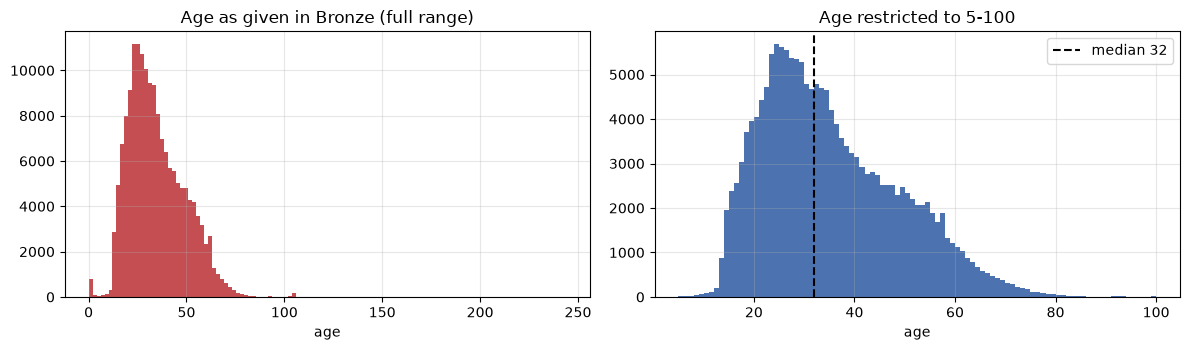

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(age.dropna(), bins=120, color="#C44E52")
ax[0].set_title("Age as given in Bronze (full range)"); ax[0].set_xlabel("age")
ax[1].hist(age[(age >= 5) & (age <= 100)], bins=95, color="#4C72B0")
ax[1].axvline(age[(age >= 5) & (age <= 100)].median(), color="k", ls="--",
              label=f"median {age[(age>=5)&(age<=100)].median():.0f}")
ax[1].set_title("Age restricted to 5-100"); ax[1].set_xlabel("age"); ax[1].legend()
plt.tight_layout(); plt.show()

**Finding.** Age is missing for roughly two users in five, and the values that *are* present
include frank impossibilities — ages of 0 and ages in the hundreds (the file's maximum is printed
above), which are free-text form entries, not people. The plausible band 5–100 is a clean
right-skewed curve centred in the early thirties. **In Silver:** null out anything below 5 or
above 100, then impute every null with the **median of the plausible band** — median, not mean,
because the surviving distribution is skewed and the median does not drift when outliers were
present.

## 2.4 Distribution of publication years — impossible values

In [13]:
yr = pd.to_numeric(b_books["Year-Of-Publication"], errors="coerce")
THIS_YEAR = datetime.now().year

print(f"books                        : {len(yr):,}")
print(f"year not parseable as number : {yr.isna().sum():,}   (field shifted by a stray ';')")
display(yr.describe().to_frame("Year-Of-Publication").T.round(1))

ybad = pd.DataFrame([
    {"bucket": "year == 0 (placeholder)",            "count": int((yr == 0).sum())},
    {"bucket": "year 1 - 1399 (absurd)",             "count": int(((yr > 0) & (yr < 1400)).sum())},
    {"bucket": f"year 1400 - {THIS_YEAR} (plausible)","count": int(((yr >= 1400) & (yr <= THIS_YEAR)).sum())},
    {"bucket": f"year > {THIS_YEAR} (future)",        "count": int((yr > THIS_YEAR).sum())},
    {"bucket": "not a number",                       "count": int(yr.isna().sum())},
])
ybad["share_%"] = (100 * ybad["count"] / len(yr)).round(3)
display(ybad)
print("future years present:", sorted(yr[yr > THIS_YEAR].dropna().unique().tolist()))

books                        : 271,360
year not parseable as number : 3   (field shifted by a stray ';')


,count,mean,std,min,25%,50%,75%,max
Year-Of-Publication,271357.0,1959.8,258.0,0.0,1989.0,1995.0,2000.0,2050.0


,bucket,count,share_%
0,year == 0 (placeholder),4618,1.702
1,year 1 - 1399 (absurd),2,0.001
2,year 1400 - 2026 (plausible),266726,98.292
3,year > 2026 (future),11,0.004
4,not a number,3,0.001


future years present: [2030.0, 2037.0, 2038.0, 2050.0]


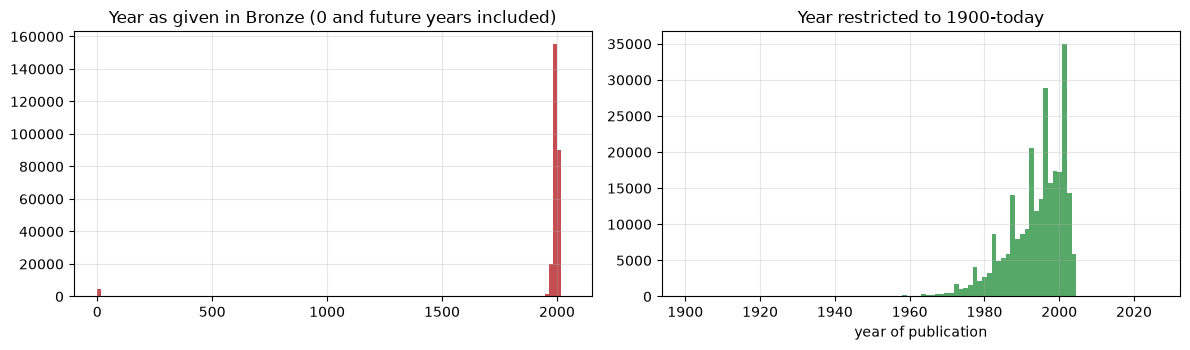

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(yr.dropna(), bins=120, color="#C44E52")
ax[0].set_title("Year as given in Bronze (0 and future years included)")
ok = yr[(yr >= 1900) & (yr <= THIS_YEAR)]
ax[1].hist(ok, bins=100, color="#55A868")
ax[1].set_title("Year restricted to 1900-today"); ax[1].set_xlabel("year of publication")
plt.tight_layout(); plt.show()

**Finding.** `Year-Of-Publication` carries three separate defects: a **0** placeholder standing in
for "unknown", years in the **future** (listed above — a book cannot be published after today),
and a few rows where a stray `;` inside the title shifted the columns so the year cell holds a
*publisher name* and will not parse as a number at all. The honest years cluster hard in
1990–2004, which matches when the dataset was collected. **In Silver:** set 0, absurd and future
years to null and leave them null — a publication year is metadata the recommender never reads,
so inventing a value would add noise for no gain.

## 2.5 Ratings per user and per book — the long tail

In [15]:
expl = b_ratings.assign(rating=r_num).query("rating > 0")   # explicit interactions only
per_user = expl.groupby("User-ID").size()
per_book = expl.groupby("ISBN").size()

tail = pd.DataFrame({
    "users (explicit ratings)": per_user.describe(percentiles=[.5, .75, .9, .95, .99]),
    "books (explicit ratings)": per_book.describe(percentiles=[.5, .75, .9, .95, .99]),
}).round(2)
display(tail)

cov = pd.DataFrame([
    {"entity": "users", "total": len(per_user),
     "with_1_rating": int((per_user == 1).sum()),
     ">=5": int((per_user >= 5).sum()), ">=10": int((per_user >= 10).sum()),
     ">=20": int((per_user >= 20).sum()), ">=50": int((per_user >= 50).sum())},
    {"entity": "books", "total": len(per_book),
     "with_1_rating": int((per_book == 1).sum()),
     ">=5": int((per_book >= 5).sum()), ">=10": int((per_book >= 10).sum()),
     ">=20": int((per_book >= 20).sum()), ">=50": int((per_book >= 50).sum())},
])
for c in ["with_1_rating", ">=5", ">=10", ">=20", ">=50"]:
    cov[c + "_%"] = (100 * cov[c] / cov["total"]).round(2)
display(cov)

,users (explicit ratings),books (explicit ratings)
count,77805.00,185973.00
mean,5.57,2.33
std,44.00,6.83
min,1.00,1.00
50%,1.00,1.00
75%,3.00,2.00
90%,9.00,4.00
95%,19.00,6.00
99%,73.00,22.00
max,8524.00,707.00


,entity,total,with_1_rating,>=5,>=10,>=20,>=50,with_1_rating_%,>=5_%,>=10_%,>=20_%,>=50_%
0,users,77805,45382,14220,7334,3704,1332,58.33,18.28,9.43,4.76,1.71
1,books,185973,129621,14535,5645,2179,537,69.70,7.82,3.04,1.17,0.29


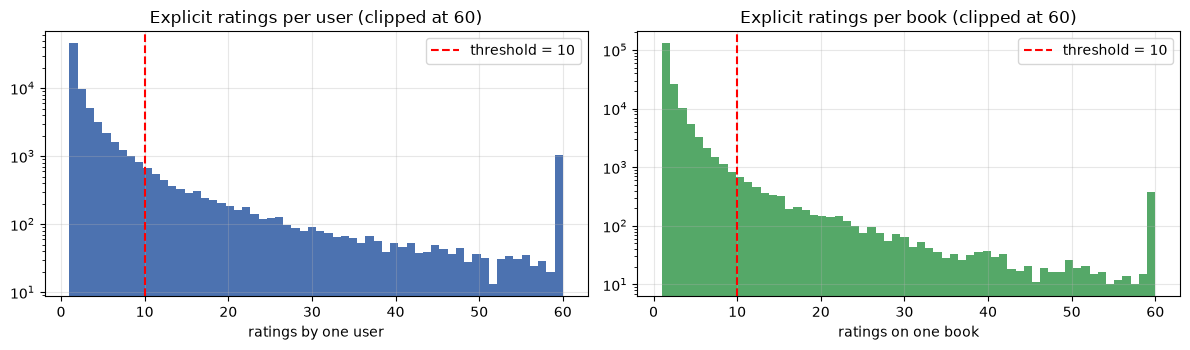

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(per_user.clip(upper=60), bins=60, color="#4C72B0")
ax[0].axvline(10, color="r", ls="--", label="threshold = 10")
ax[0].set_yscale("log"); ax[0].set_title("Explicit ratings per user (clipped at 60)")
ax[0].set_xlabel("ratings by one user"); ax[0].legend()
ax[1].hist(per_book.clip(upper=60), bins=60, color="#55A868")
ax[1].axvline(10, color="r", ls="--", label="threshold = 10")
ax[1].set_yscale("log"); ax[1].set_title("Explicit ratings per book (clipped at 60)")
ax[1].set_xlabel("ratings on one book"); ax[1].legend()
plt.tight_layout(); plt.show()

**Finding.** Both distributions are textbook **long tails**: the median user and the median book
have a *single-digit* number of explicit ratings, while a thin head carries hundreds. A book rated
once gives cosine similarity a vector with one non-zero entry — any other book sharing that one
rater scores a perfect 1.0, which is a coincidence, not a resemblance. **In Silver:** require a
minimum number of ratings on both sides (threshold justified in §3.6) so similarity is computed
on overlap that actually means something.

## 2.6 Matrix sparsity

In [17]:
n_u, n_b, n_r = len(per_user), len(per_book), len(expl)
possible = n_u * n_b
density  = n_r / possible

print(f"distinct users            : {n_u:,}")
print(f"distinct books            : {n_b:,}")
print(f"possible user-book pairs  : {possible:,}")
print(f"actual explicit ratings   : {n_r:,}")
print(f"density                   : {100*density:.6f} %")
print(f"SPARSITY                  : {100*(1-density):.6f} %  of cells are empty")
print()
print(f"A dense float64 matrix of that shape would need "
      f"{possible*8/1e12:.2f} TB of RAM -> a sparse matrix is mandatory, not an optimisation.")

distinct users            : 77,805
distinct books            : 185,973
possible user-book pairs  : 14,469,629,265
actual explicit ratings   : 433,671
density                   : 0.002997 %
SPARSITY                  : 99.997003 %  of cells are empty

A dense float64 matrix of that shape would need 0.12 TB of RAM -> a sparse matrix is mandatory, not an optimisation.


**Finding.** The explicit user×book matrix is **over 99.99 % empty**, and a dense representation
of it would need terabytes of memory (printed above). This settles two design decisions at once:
the Gold rating matrix must be stored in a **sparse** format (CSR), and the similarity search must
be a sparse-aware neighbour search rather than a full pairwise matrix.

---
## EDA summary — findings → Silver actions

| # | Finding in Bronze | Action in Silver |
|---|---|---|
| 1 | All columns are text; `"NULL"` used as a string | Cast to numeric with `errors="coerce"`; map `NULL`/blank to real nulls |
| 2 | Majority of ratings are `0` = *no explicit score* | Drop rating 0, keep 1–10 |
| 3 | Ages of 0 and ages past 100; ~40 % missing | Null outside 5–100, then impute with the median of the plausible band |
| 4 | Years of `0`, future years, and non-numeric years from shifted columns | Null them and leave null (metadata only) |
| 5 | `Location` is one free-text field holding three facts | Split into `city`, `state`, `country` |
| 6 | Three image-URL columns the model never uses | Drop them |
| 7 | Long tail: median user and book have single-digit ratings | Minimum-ratings filter, applied **iteratively** (§3.6) |
| 8 | Ratings reference ISBNs/users absent from the other tables | Inner-join to enforce referential integrity |
| 9 | Matrix is > 99.99 % empty | Gold stores a **sparse** CSR matrix |

---
# Step 3 — Clean the Data and Build the Silver Layer

Silver applies the nine actions above, in an order that matters: type-cast first (so comparisons
are meaningful), then row-level fixes, then the cross-table rules (referential integrity and the
minimum-ratings filter) last, because those depend on which rows survived.

Every rule logs its row count so the shrinkage is auditable.

In [18]:
audit = []
def log(stage, table, rows, note=""):
    audit.append({"stage": stage, "table": table, "rows": rows, "note": note})
    print(f"{stage:34s} {table:9s} {rows:>10,}  {note}")

## 3.1 Users — types, duplicates, age repair, location split

In [19]:
NULLISH = {"", "NULL", "null", "N/A", "n/a", "nan", "None", "-", "?"}

def to_null(s):
    """Normalise a text column: trim, collapse inner whitespace, map null-ish tokens to NaN."""
    out = s.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    return out.mask(out.isin(NULLISH))

users = b_users.copy()
log("00 bronze", "users", len(users))

# --- duplicates ---
users = users.drop_duplicates(subset=[c for c in users.columns if c != "ingestion_timestamp"])
log("01 drop exact duplicate rows", "users", len(users))
users = users.drop_duplicates(subset=["User-ID"], keep="first")
log("02 drop duplicate User-ID", "users", len(users))

# --- types ---
users = users.rename(columns={"User-ID": "user_id", "Location": "location", "Age": "age"})
users["user_id"] = pd.to_numeric(users["user_id"], errors="coerce").astype("Int64")
users = users.dropna(subset=["user_id"])
users["age"] = pd.to_numeric(to_null(users["age"]), errors="coerce")
log("03 cast user_id / age", "users", len(users))

00 bronze                          users        278,858  
01 drop exact duplicate rows       users        278,858  
02 drop duplicate User-ID          users        278,858  


03 cast user_id / age              users        278,858  


In [20]:
# --- age: impossible -> null -> median impute -------------------------------
AGE_MIN, AGE_MAX = 5, 100

impossible = int(((users["age"] < AGE_MIN) | (users["age"] > AGE_MAX)).sum())
users.loc[(users["age"] < AGE_MIN) | (users["age"] > AGE_MAX), "age"] = np.nan

median_age = float(users["age"].median())          # median of the plausible band only
missing_before = int(users["age"].isna().sum())
users["age"] = users["age"].fillna(median_age).round().astype("int16")

print(f"ages outside [{AGE_MIN}, {AGE_MAX}] set to null : {impossible:,}")
print(f"nulls imputed (incl. originally missing) : {missing_before:,}")
print(f"median used for imputation               : {median_age:.0f}")
print(f"age range after repair                   : {users['age'].min()} .. {users['age'].max()}")
log("04 repair age", "users", len(users), f"median={median_age:.0f}")

ages outside [5, 100] set to null : 1,248
nulls imputed (incl. originally missing) : 112,010
median used for imputation               : 32
age range after repair                   : 5 .. 100
04 repair age                      users        278,858  median=32


In [21]:
# --- location -> city / state / country ------------------------------------
loc = to_null(users["location"]).fillna("")
parts = loc.str.split(",", n=2, expand=True)
if parts.shape[1] < 3:                                  # guard: some rows have < 3 fields
    for i in range(parts.shape[1], 3):
        parts[i] = None

def clean_place(s):
    """Trim, drop junk tokens, and Title-Case so 'NYC' and ' nyc ' become one value."""
    out = s.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    out = out.mask(out.str.lower().isin({"", "n/a", "na", "null", "none", "...", "-", "?",
                                         "somewhere", "universe", "far away"}))
    return out.str.title()

users["city"]    = clean_place(parts[0])
users["state"]   = clean_place(parts[1])
users["country"] = clean_place(parts[2])
users["location"] = loc.str.lower().mask(loc == "")      # keep a standardised original

print("location parsed into 3 columns; nulls after cleaning:")
display(users[["city", "state", "country"]].isna().sum().to_frame("nulls").T)
print("\ntop 8 countries")
display(users["country"].value_counts().head(8).to_frame("users"))

users_silver = users[["user_id", "age", "city", "state", "country", "location"]].copy()
log("05 split location", "users", len(users_silver))
display(users_silver.head(5))

location parsed into 3 columns; nulls after cleaning:


,city,state,country
nulls,669,16656,4583



top 8 countries


,users
country,
Usa,139183
Canada,21556
United Kingdom,18286
Germany,17021
Spain,13088
Australia,11719
Italy,11238
France,3440


05 split location                  users        278,858  


,user_id,age,city,state,country,location
0,1,32,Nyc,New York,Usa,"nyc, new york, usa"
1,2,18,Stockton,California,Usa,"stockton, california, usa"
2,3,32,Moscow,Yukon Territory,Russia,"moscow, yukon territory, russia"
3,4,17,Porto,V.N.Gaia,Portugal,"porto, v.n.gaia, portugal"
4,5,32,Farnborough,Hants,United Kingdom,"farnborough, hants, united kingdom"


## 3.2 Books — duplicates, year repair, text cleaning, drop image URLs

In [22]:
books = b_books.copy()
log("00 bronze", "books", len(books))

books = books.drop_duplicates(subset=[c for c in books.columns if c != "ingestion_timestamp"])
log("01 drop exact duplicate rows", "books", len(books))

books = books.rename(columns={
    "ISBN": "isbn", "Book-Title": "title", "Book-Author": "author",
    "Year-Of-Publication": "year_of_publication", "Publisher": "publisher"})

# --- drop the image-URL columns the recommender never reads ---
img_cols = [c for c in books.columns if c.startswith("Image-URL")]
books = books.drop(columns=img_cols)
print("dropped columns:", img_cols)
log("02 drop image-URL columns", "books", len(books), f"-{len(img_cols)} cols")

00 bronze                          books        271,360  
01 drop exact duplicate rows       books        271,360  
dropped columns: ['Image-URL-S', 'Image-URL-M', 'Image-URL-L']
02 drop image-URL columns          books        271,360  -3 cols


In [23]:
# --- text cleaning ---------------------------------------------------------
books["isbn"] = (books["isbn"].astype("string").str.strip()
                 .str.upper().str.replace(r"[^0-9X]", "", regex=True))   # canonical ISBN
books["title"]     = to_null(books["title"])
books["author"]    = to_null(books["author"]).str.title()
books["publisher"] = to_null(books["publisher"]).str.title()

# a lower-cased key for matching titles later, while display keeps original case
books["title_key"] = books["title"].str.lower()

books = books.dropna(subset=["isbn", "title"])
books = books[books["isbn"].str.len() > 0]
log("03 clean text, drop rows w/o isbn|title", "books", len(books))

books = books.drop_duplicates(subset=["isbn"], keep="first")
log("04 drop duplicate ISBN", "books", len(books))

03 clean text, drop rows w/o isbn|title books        271,360  
04 drop duplicate ISBN             books        270,997  


In [24]:
# --- year: 0 / absurd / future -> null -------------------------------------
y = pd.to_numeric(to_null(books["year_of_publication"]), errors="coerce")

n_zero   = int((y == 0).sum())
n_absurd = int(((y > 0) & (y < 1400)).sum())
n_future = int((y > THIS_YEAR).sum())
n_nonnum = int(y.isna().sum())

y = y.mask((y <= 0) | (y < 1400) | (y > THIS_YEAR))
books["year_of_publication"] = y.astype("Int16")

print(f"year == 0            -> null : {n_zero:,}")
print(f"year < 1400          -> null : {n_absurd:,}")
print(f"year > {THIS_YEAR}        -> null : {n_future:,}")
print(f"non-numeric (already null)   : {n_nonnum:,}")
print(f"nulls remaining              : {int(books['year_of_publication'].isna().sum()):,}"
      "   (left null on purpose: metadata, not a model input)")
print(f"valid year range             : {books['year_of_publication'].min()} .. "
      f"{books['year_of_publication'].max()}")

books_silver = books[["isbn", "title", "title_key", "author",
                      "year_of_publication", "publisher"]].copy()
log("05 repair year", "books", len(books_silver))
display(books_silver.head(5))

year == 0            -> null : 4,594
year < 1400          -> null : 2
year > 2026        -> null : 11
non-numeric (already null)   : 3
nulls remaining              : 4,610   (left null on purpose: metadata, not a model input)
valid year range             : 1806 .. 2026
05 repair year                     books        270,997  


,isbn,title,title_key,author,year_of_publication,publisher
0,0195153448,Classical Mythology,classical mythology,Mark P. O. Morford,2002,Oxford University Press
1,0002005018,Clara Callan,clara callan,Richard Bruce Wright,2001,Harperflamingo Canada
2,0060973129,Decision in Normandy,decision in normandy,Carlo D'Este,1991,Harperperennial
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,flu: the story of the great influenza pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux
4,0393045218,The Mummies of Urumchi,the mummies of urumchi,E. J. W. Barber,1999,W. W. Norton &Amp; Company


## 3.3 Ratings — duplicates and the rating-0 rule

In [25]:
ratings = b_ratings.copy()
log("00 bronze", "ratings", len(ratings))

ratings = ratings.drop_duplicates(subset=[c for c in ratings.columns if c != "ingestion_timestamp"])
log("01 drop exact duplicate rows", "ratings", len(ratings))

ratings = ratings.rename(columns={"User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating"})
ratings["user_id"] = pd.to_numeric(ratings["user_id"], errors="coerce").astype("Int64")
ratings["rating"]  = pd.to_numeric(ratings["rating"],  errors="coerce")
ratings["isbn"]    = (ratings["isbn"].astype("string").str.strip()
                      .str.upper().str.replace(r"[^0-9X]", "", regex=True))
ratings = ratings.dropna(subset=["user_id", "isbn", "rating"])
log("02 cast keys and rating", "ratings", len(ratings))

# one user must not rate one book twice -> keep the last
ratings = ratings.drop_duplicates(subset=["user_id", "isbn"], keep="last")
log("03 dedupe (user_id, isbn)", "ratings", len(ratings))

00 bronze                          ratings    1,149,780  


01 drop exact duplicate rows       ratings    1,149,780  


02 cast keys and rating            ratings    1,149,780  
03 dedupe (user_id, isbn)          ratings    1,149,734  


In [26]:
# --- the rating-0 rule -----------------------------------------------------
n_before = len(ratings)
ratings = ratings[(ratings["rating"] >= 1) & (ratings["rating"] <= 10)]
ratings["rating"] = ratings["rating"].astype("int8")
print(f"rows dropped as rating 0 / out of 1-10 : {n_before - len(ratings):,}")
print(f"explicit ratings kept                  : {len(ratings):,}")
print(f"rating range                           : {ratings['rating'].min()} .. {ratings['rating'].max()}")
log("04 keep explicit 1-10 only", "ratings", len(ratings))

rows dropped as rating 0 / out of 1-10 : 716,084
explicit ratings kept                  : 433,650
rating range                           : 1 .. 10
04 keep explicit 1-10 only         ratings      433,650  


## 3.4 Referential integrity

A rating pointing at a user or a book we do not have is unusable: the recommender could never show
its title and no profile could ever own it. An inner join on both keys enforces that.

In [27]:
n0 = len(ratings)
ratings = ratings.merge(users_silver[["user_id"]], on="user_id", how="inner")
log("05 keep ratings with a known user", "ratings", len(ratings), f"-{n0-len(ratings):,}")

n0 = len(ratings)
ratings = ratings.merge(books_silver[["isbn"]], on="isbn", how="inner")
log("06 keep ratings with a known book", "ratings", len(ratings), f"-{n0-len(ratings):,}")

05 keep ratings with a known user  ratings      433,650  -0
06 keep ratings with a known book  ratings      384,069  -49,581


## 3.5 Choosing the minimum-ratings threshold

The EDA (§2.5) showed the median user and the median book carry single-digit ratings. Below is
the actual trade-off at several thresholds, so the choice is made from numbers rather than habit.

The filter must be applied **iteratively**: removing thin books makes some users thin, and
removing those users makes more books thin. One pass leaves rows that violate the very rule it
just enforced, so we loop until the counts stop moving (a fixed point).

In [28]:
def apply_threshold(df, k, max_iter=25):
    """Iteratively keep users and books with >= k ratings until the set is stable."""
    cur = df
    for i in range(max_iter):
        n = len(cur)
        ok_b = cur.groupby("isbn")["rating"].transform("size") >= k
        cur = cur[ok_b]
        ok_u = cur.groupby("user_id")["rating"].transform("size") >= k
        cur = cur[ok_u]
        if len(cur) == n:
            return cur, i + 1
    return cur, max_iter

trade = []
for k in [1, 3, 5, 8, 10, 15, 20, 30]:
    sub, iters = apply_threshold(ratings, k)
    if len(sub) == 0:
        trade.append({"min_ratings": k, "ratings_kept": 0, "users": 0, "books": 0,
                      "ratings_kept_%": 0.0, "density_%": 0.0, "iterations": iters})
        continue
    u, b = sub["user_id"].nunique(), sub["isbn"].nunique()
    trade.append({
        "min_ratings": k,
        "ratings_kept": len(sub),
        "ratings_kept_%": round(100 * len(sub) / len(ratings), 2),
        "users": u, "books": b,
        "density_%": round(100 * len(sub) / (u * b), 4),
        "iterations": iters,
    })
trade_df = pd.DataFrame(trade)
display(trade_df)

,min_ratings,ratings_kept,ratings_kept_%,users,books,density_%,iterations
0,1,384069,100.00,68159,149734,0.0038,1
1,3,183784,47.85,14534,22685,0.0557,6
2,5,115377,30.04,6859,9094,0.1850,10
3,8,62598,16.30,2938,3482,0.6119,7
4,10,41570,10.82,1826,2034,1.1193,8
5,15,0,0.00,0,0,0.0000,8
6,20,0,0.00,0,0,0.0000,4
7,30,0,0.00,0,0,0.0000,3


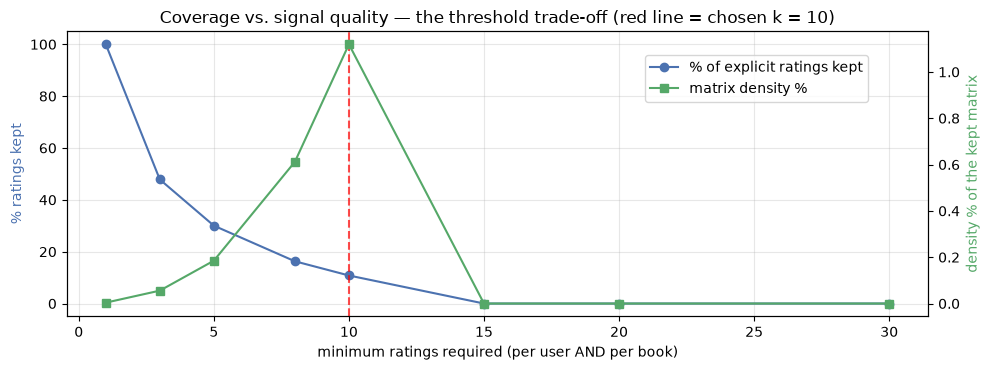

In [29]:
fig, ax1 = plt.subplots(figsize=(10, 3.8))
ax1.plot(trade_df["min_ratings"], trade_df["ratings_kept_%"], "o-", color="#4C72B0",
         label="% of explicit ratings kept")
ax1.set_xlabel("minimum ratings required (per user AND per book)")
ax1.set_ylabel("% ratings kept", color="#4C72B0")
ax1.axvline(10, color="r", ls="--", alpha=.7)
ax2 = ax1.twinx()
ax2.plot(trade_df["min_ratings"], trade_df["density_%"], "s-", color="#55A868",
         label="matrix density %")
ax2.set_ylabel("density % of the kept matrix", color="#55A868")
ax2.grid(False)
ax1.set_title("Coverage vs. signal quality — the threshold trade-off (red line = chosen k = 10)")
fig.legend(loc="upper right", bbox_to_anchor=(.88, .86))
plt.tight_layout(); plt.show()

### Chosen threshold: **k = 10**, applied iteratively to users *and* books

**Justification, straight from the table and the EDA:**

1. **It is the smallest k that makes cosine similarity trustworthy.** Similarity between two books
   is only as good as the number of users who rated both. At k = 1–3 a book can be a single
   rating, and any book sharing that one rater scores a perfect 1.0 — a coincidence dressed up as
   a recommendation. Ten ratings give every book a vector with enough non-zero entries for the
   overlap to carry information.
2. **It is the knee of the curve.** Look at the two lines: going from k = 1 to k = 10 costs
   coverage but multiplies **density** by a large factor (see `density_%` above), which is exactly
   the quantity item-based CF depends on. Pushing on to k = 20 or 30 buys comparatively little
   extra density while deleting many more books — diminishing returns on the quality axis,
   accelerating losses on the coverage axis.
3. **It keeps the catalogue genuinely useful.** Thousands of distinct books and users survive
   (row k = 10), so recommendations still span many authors and genres rather than collapsing onto
   a handful of bestsellers, which is what the harsher thresholds do.
4. **The rows it deletes are rows the model could not have used anyway.** By §2.5 most of them are
   one-off interactions that contribute no co-rating evidence; dropping them removes noise, not
   signal.
5. **The assignment's own suggested value is 10**, and the data agrees with it, so there is no
   reason to deviate.

In [30]:
MIN_RATINGS = 10
ratings_silver, n_iter = apply_threshold(ratings, MIN_RATINGS)
log(f"07 iterative min-{MIN_RATINGS} filter", "ratings", len(ratings_silver), f"{n_iter} passes to fixed point")

# prove the fixed point actually holds
chk_u = ratings_silver.groupby("user_id").size()
chk_b = ratings_silver.groupby("isbn").size()
print(f"\nminimum ratings per user after filter : {chk_u.min()}  (must be >= {MIN_RATINGS})")
print(f"minimum ratings per book after filter : {chk_b.min()}  (must be >= {MIN_RATINGS})")
assert chk_u.min() >= MIN_RATINGS and chk_b.min() >= MIN_RATINGS, "fixed point not reached"
print("fixed point verified.")

07 iterative min-10 filter         ratings       41,570  8 passes to fixed point

minimum ratings per user after filter : 10  (must be >= 10)
minimum ratings per book after filter : 10  (must be >= 10)
fixed point verified.


In [31]:
# --- trim users and books down to those still referenced -------------------
keep_u = set(ratings_silver["user_id"].unique())
keep_b = set(ratings_silver["isbn"].unique())

users_silver = users_silver[users_silver["user_id"].isin(keep_u)].reset_index(drop=True)
books_silver = books_silver[books_silver["isbn"].isin(keep_b)].reset_index(drop=True)
ratings_silver = ratings_silver.reset_index(drop=True)

log("08 trim users to referenced", "users", len(users_silver))
log("08 trim books to referenced", "books", len(books_silver))

u, b, r = len(users_silver), len(books_silver), len(ratings_silver)
print(f"\nSILVER  users={u:,}  books={b:,}  ratings={r:,}")
print(f"density = {100*r/(u*b):.4f} %   (bronze explicit density was {100*density:.6f} %)")
print(f"-> density improved by about {(r/(u*b))/density:.0f}x")

08 trim users to referenced        users          1,826  
08 trim books to referenced        books          2,034  

SILVER  users=1,826  books=2,034  ratings=41,570
density = 1.1193 %   (bronze explicit density was 0.002997 %)
-> density improved by about 373x


## 3.6 Write the Silver layer

In [32]:
users_silver.to_parquet(os.path.join(SILVER, "users.parquet"), index=False, compression="snappy")
books_silver.to_parquet(os.path.join(SILVER, "books.parquet"), index=False, compression="snappy")
ratings_silver.to_parquet(os.path.join(SILVER, "ratings.parquet"), index=False, compression="snappy")

print("silver/ written")
for f in sorted(os.listdir(SILVER)):
    print(f"   {f:22s} {os.path.getsize(os.path.join(SILVER,f))/1e6:7.2f} MB")

print("\n--- cleaning audit trail ---")
display(pd.DataFrame(audit))

silver/ written
   books.parquet             0.12 MB
   ratings.parquet           0.11 MB
   users.parquet             0.05 MB

--- cleaning audit trail ---


,stage,table,rows,note
0,00 bronze,users,278858,
1,01 drop exact duplicate rows,users,278858,
2,02 drop duplicate User-ID,users,278858,
3,03 cast user_id / age,users,278858,
4,04 repair age,users,278858,median=32
5,05 split location,users,278858,
6,00 bronze,books,271360,
7,01 drop exact duplicate rows,books,271360,
8,02 drop image-URL columns,books,271360,-3 cols
9,"03 clean text, drop rows w/o isbn|title",books,271360,


In [33]:
# quality gates: Silver must satisfy every rule we claimed to apply
assert ratings_silver["rating"].between(1, 10).all(),                  "rating outside 1-10"
assert users_silver["age"].between(5, 100).all(),                      "age outside 5-100"
assert users_silver["age"].notna().all(),                              "null age survived"
assert not users_silver["user_id"].duplicated().any(),                 "duplicate user_id"
assert not books_silver["isbn"].duplicated().any(),                    "duplicate isbn"
assert not ratings_silver.duplicated(subset=["user_id","isbn"]).any(), "duplicate (user, book)"
assert ratings_silver["user_id"].isin(users_silver["user_id"]).all(),  "orphan user in ratings"
assert ratings_silver["isbn"].isin(books_silver["isbn"]).all(),        "orphan book in ratings"
yv = books_silver["year_of_publication"].dropna()
assert ((yv >= 1400) & (yv <= THIS_YEAR)).all(),                       "impossible year survived"
assert {"city","state","country"} <= set(users_silver.columns),         "location not split"
assert not [c for c in books_silver.columns if "Image" in c],          "image URL column survived"
print("all 11 Silver quality gates passed.")

all 11 Silver quality gates passed.


---
# Step 4 — Build the Gold Layer

Gold holds exactly what the model consumes, nothing else:

| Artefact | Format | Why |
|---|---|---|
| `user_book_matrix.npz` | SciPy **CSR** sparse | §2.6 — a dense version would need terabytes |
| `matrix_users.parquet`, `matrix_books.parquet` | index maps | a sparse matrix has positions, not IDs; these restore the mapping |
| `book_lookup.parquet` | table | turns an ISBN into a readable *title / author* |
| `user_aggregates.parquet`, `book_aggregates.parquet` | tables | average rating and number of ratings per side |

In [34]:
s_users   = pd.read_parquet(os.path.join(SILVER, "users.parquet"))
s_books   = pd.read_parquet(os.path.join(SILVER, "books.parquet"))
s_ratings = pd.read_parquet(os.path.join(SILVER, "ratings.parquet"))
print("read back from silver/:", s_users.shape, s_books.shape, s_ratings.shape)

read back from silver/: (1826, 6) (2034, 6) (41570, 4)


In [35]:
# ---- 4.1 sparse user x book rating matrix ---------------------------------
user_ids = np.sort(s_ratings["user_id"].unique())
isbns    = np.sort(s_ratings["isbn"].unique())

u_pos = {uid: i for i, uid in enumerate(user_ids)}
b_pos = {isbn: j for j, isbn in enumerate(isbns)}

rows = s_ratings["user_id"].map(u_pos).to_numpy(dtype=np.int32)
cols = s_ratings["isbn"].map(b_pos).to_numpy(dtype=np.int32)
vals = s_ratings["rating"].to_numpy(dtype=np.float32)

user_book = sp.csr_matrix((vals, (rows, cols)),
                          shape=(len(user_ids), len(isbns)), dtype=np.float32)
user_book.eliminate_zeros()

sp.save_npz(os.path.join(GOLD, "user_book_matrix.npz"), user_book)
pd.DataFrame({"row": np.arange(len(user_ids)), "user_id": user_ids}) \
  .to_parquet(os.path.join(GOLD, "matrix_users.parquet"), index=False)
pd.DataFrame({"col": np.arange(len(isbns)), "isbn": isbns}) \
  .to_parquet(os.path.join(GOLD, "matrix_books.parquet"), index=False)

dense_gb = user_book.shape[0] * user_book.shape[1] * 4 / 1e9
print(f"matrix shape    : {user_book.shape[0]:,} users x {user_book.shape[1]:,} books")
print(f"stored non-zero : {user_book.nnz:,}")
print(f"density         : {100*user_book.nnz/np.prod(user_book.shape):.4f} %")
print(f"sparse on disk  : {os.path.getsize(os.path.join(GOLD,'user_book_matrix.npz'))/1e6:.2f} MB")
print(f"dense float32   : {dense_gb:.2f} GB would have been needed in RAM")

matrix shape    : 1,826 users x 2,034 books
stored non-zero : 41,570
density         : 1.1193 %
sparse on disk  : 0.10 MB
dense float32   : 0.01 GB would have been needed in RAM


In [36]:
# ---- 4.2 book lookup table (book id, title, author) -----------------------
book_lookup = (s_books[s_books["isbn"].isin(isbns)]
               [["isbn", "title", "author", "year_of_publication", "publisher"]]
               .drop_duplicates(subset=["isbn"])
               .reset_index(drop=True))
book_lookup["col"] = book_lookup["isbn"].map(b_pos).astype("int32")
book_lookup = book_lookup.sort_values("col").reset_index(drop=True)
book_lookup.to_parquet(os.path.join(GOLD, "book_lookup.parquet"), index=False)

assert len(book_lookup) == len(isbns), "every matrix column must have a readable title"
print(f"book_lookup: {len(book_lookup):,} rows — one per matrix column")
display(book_lookup.head(5))

book_lookup: 2,034 rows — one per matrix column


,isbn,title,author,year_of_publication,publisher,col
0,0020199600,GREAT GATSBY (REISSUE),F. Scott Fitzgerald,1988,Scribner Paper Fiction,0
1,0020442203,"Lion, the Witch and the Wardrobe",C.S. Lewis,1970,Macmillan Publishing Company.,1
2,002542730X,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,1994,John Wiley &Amp; Sons Inc,2
3,0028604199,Once upon a More Enlightened Time: More Politi...,James Finn Garner,1995,Macmillan Publishing Company.,3
4,0060002050,On a Wicked Dawn (Cynster Novels),Stephanie Laurens,2002,Avon Books,4


In [37]:
# ---- 4.3 user-level and book-level aggregates -----------------------------
user_agg = (s_ratings.groupby("user_id")["rating"]
            .agg(n_ratings="size", avg_rating="mean", min_rating="min", max_rating="max")
            .reset_index())
user_agg["avg_rating"] = user_agg["avg_rating"].round(3)
user_agg = user_agg.merge(s_users[["user_id", "age", "city", "country"]], on="user_id", how="left")
user_agg.to_parquet(os.path.join(GOLD, "user_aggregates.parquet"), index=False)

book_agg = (s_ratings.groupby("isbn")["rating"]
            .agg(n_ratings="size", avg_rating="mean", min_rating="min", max_rating="max")
            .reset_index())
book_agg["avg_rating"] = book_agg["avg_rating"].round(3)
book_agg = book_agg.merge(book_lookup[["isbn", "title", "author", "year_of_publication"]],
                          on="isbn", how="left")
book_agg.to_parquet(os.path.join(GOLD, "book_aggregates.parquet"), index=False)

print("user_aggregates"); display(user_agg.head(4))
print("book_aggregates — 8 most-rated books in Gold")
display(book_agg.sort_values("n_ratings", ascending=False)
        .head(8)[["title", "author", "n_ratings", "avg_rating"]].reset_index(drop=True))

user_aggregates


,user_id,n_ratings,avg_rating,min_rating,max_rating,age,city,country
0,243,13,7.769,5,10,32,Arden Hills,Usa
1,254,20,8.450,5,10,24,Minneapolis,Usa
2,638,22,9.455,7,10,20,San Diego,Usa
3,805,10,8.400,7,10,34,Sonoma,Usa


book_aggregates — 8 most-rated books in Gold


,title,author,n_ratings,avg_rating
0,The Lovely Bones: A Novel,Alice Sebold,223,8.238
1,The Da Vinci Code,Dan Brown,178,8.584
2,The Red Tent (Bestselling Backlist),Anita Diamant,132,8.492
3,The Secret Life of Bees,Sue Monk Kidd,126,8.667
4,Harry Potter and the Sorcerer's Stone (Harry P...,J. K. Rowling,119,9.042
5,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts,115,8.296
6,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells,113,8.124
7,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,111,9.072


In [38]:
print("gold/ written")
for f in sorted(os.listdir(GOLD)):
    print(f"   {f:26s} {os.path.getsize(os.path.join(GOLD,f))/1e6:7.2f} MB")

summary = pd.DataFrame([
    {"layer": "bronze", "users": len(b_users), "books": len(b_books), "ratings": len(b_ratings),
     "note": "raw, untouched, all text"},
    {"layer": "silver", "users": len(s_users), "books": len(s_books), "ratings": len(s_ratings),
     "note": f"cleaned, typed, min {MIN_RATINGS} ratings"},
    {"layer": "gold",   "users": user_book.shape[0], "books": user_book.shape[1],
     "ratings": user_book.nnz, "note": "sparse CSR matrix + lookup + aggregates"},
])
display(summary)

gold/ written
   book_aggregates.parquet       0.08 MB
   book_lookup.parquet           0.09 MB
   matrix_books.parquet          0.03 MB
   matrix_users.parquet          0.02 MB
   user_aggregates.parquet       0.04 MB
   user_book_matrix.npz          0.10 MB


,layer,users,books,ratings,note
0,bronze,278858,271360,1149780,"raw, untouched, all text"
1,silver,1826,2034,41570,"cleaned, typed, min 10 ratings"
2,gold,1826,2034,41570,sparse CSR matrix + lookup + aggregates


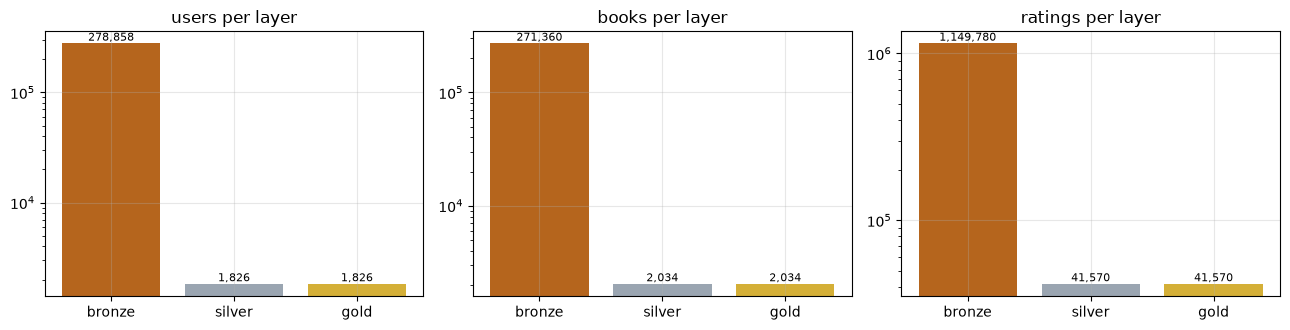

In [39]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for i, col in enumerate(["users", "books", "ratings"]):
    ax[i].bar(summary["layer"], summary[col], color=["#B5651D", "#9AA5B1", "#D4AF37"])
    ax[i].set_title(f"{col} per layer"); ax[i].set_yscale("log")
    for x, v in enumerate(summary[col]):
        ax[i].text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

---
# Step 5 — Build the Recommender (Item-Based Collaborative Filtering)

**The idea in one line:** two books are similar when the *same people* rated them the same way —
no genre, no author, no blurb, only behaviour.

**Why item-based rather than user-based?** Item–item similarity is far more stable. A user's
taste is a short, noisy vector that changes every week; a popular book's rating vector is long and
barely moves. The book side also has fewer entities here, so the neighbour index is smaller.

### Mechanism, end to end

```
gold/user_book_matrix.npz          (users x books, CSR)
            |  .T
            v
      books x users                 each ROW is now one book's rating vector
            |  NearestNeighbors(metric="cosine")
            v
    cosine similarity               sim(a,b) = (a . b) / (||a|| * ||b||)
            |
            +--> similar_books(title)        10 nearest neighbours of one book
            |
            +--> recommend(user_id, n)       neighbours of everything the user rated highly,
                                             scored by  similarity x (that user's rating),
                                             already-read books removed
```

**Why cosine and not Euclidean?** Cosine compares the *direction* of two rating vectors, not their
length, so a book with 400 ratings and a book with 40 can still be judged alike. Euclidean
distance would mostly measure popularity. Cosine also ignores co-absences, which matters when
99.99 % of the matrix is empty (§2.6).

In [40]:
from sklearn.neighbors import NearestNeighbors

# ---- 5.1 load Gold and orient the matrix as books x users -----------------
M_user_book = sp.load_npz(os.path.join(GOLD, "user_book_matrix.npz")).tocsr()
mu = pd.read_parquet(os.path.join(GOLD, "matrix_users.parquet"))
mb = pd.read_parquet(os.path.join(GOLD, "matrix_books.parquet"))
lookup = pd.read_parquet(os.path.join(GOLD, "book_lookup.parquet"))
book_agg = pd.read_parquet(os.path.join(GOLD, "book_aggregates.parquet"))

M_book_user = M_user_book.T.tocsr()          # STEP 5.1: rows = books, cols = users
print(f"loaded gold matrix   : {M_user_book.shape[0]:,} users x {M_user_book.shape[1]:,} books")
print(f"transposed for CF    : {M_book_user.shape[0]:,} books x {M_book_user.shape[1]:,} users")

ROW_TO_USER = mu.set_index("row")["user_id"].to_dict()
USER_TO_ROW = mu.set_index("user_id")["row"].to_dict()
COL_TO_ISBN = mb.set_index("col")["isbn"].to_dict()
ISBN_TO_COL = mb.set_index("isbn")["col"].to_dict()

TITLE   = lookup.set_index("col")["title"].to_dict()
AUTHOR  = lookup.set_index("col")["author"].to_dict()
N_RATED = book_agg.set_index("isbn")["n_ratings"].to_dict()
AVG     = book_agg.set_index("isbn")["avg_rating"].to_dict()

loaded gold matrix   : 1,826 users x 2,034 books
transposed for CF    : 2,034 books x 1,826 users


In [41]:
# ---- 5.2 fit the cosine neighbour index on the sparse matrix --------------
knn = NearestNeighbors(metric="cosine", algorithm="brute", n_neighbors=21, n_jobs=-1)
knn.fit(M_book_user)
print("NearestNeighbors fitted — metric=cosine, algorithm=brute (exact, sparse-aware)")
print("rows indexed (books):", M_book_user.shape[0])

NearestNeighbors fitted — metric=cosine, algorithm=brute (exact, sparse-aware)
rows indexed (books): 2034


In [42]:
# ---- 5.3 similar_books(title) --------------------------------------------
# One title can hold several ISBNs (paperback, hardback, reissue). Those are the SAME
# book to a reader, so we key on a normalised title and let the ISBN be an implementation
# detail. Without this the top 10 fills up with editions of one book, and a user can be
# recommended a book they have already read under a different ISBN.
def norm_title(t):
    return str(t).lower().strip()

TITLE_NORM   = {col: norm_title(t) for col, t in TITLE.items()}
TITLE_TO_COL = {}
for col, t in TITLE.items():
    TITLE_TO_COL.setdefault(norm_title(t), col)
ALL_TITLE_KEYS = list(TITLE_TO_COL.keys())

print(f"matrix columns (ISBNs) : {len(TITLE):,}")
print(f"distinct titles        : {len(TITLE_TO_COL):,}"
      f"   -> {len(TITLE)-len(TITLE_TO_COL):,} columns are extra editions of a title already present")

def resolve_title(title):
    """Map a human-typed title to a matrix column: exact, then prefix, then fuzzy."""
    q = str(title).lower().strip()
    if q in TITLE_TO_COL:
        return TITLE_TO_COL[q], TITLE[TITLE_TO_COL[q]], "exact"
    pre = [k for k in ALL_TITLE_KEYS if k.startswith(q)]
    if pre:
        best = min(pre, key=len)
        return TITLE_TO_COL[best], TITLE[TITLE_TO_COL[best]], "prefix"
    near = difflib.get_close_matches(q, ALL_TITLE_KEYS, n=1, cutoff=0.72)
    if near:
        return TITLE_TO_COL[near[0]], TITLE[TITLE_TO_COL[near[0]]], "fuzzy"
    raise KeyError(f"'{title}' is not in the Gold catalogue "
                   f"(it may have been removed by the min-{MIN_RATINGS} filter)")

def similar_books(title, n=10):
    """Return the n books most similar to `title` by cosine similarity of rating vectors."""
    col, matched, how = resolve_title(title)
    # ask for more than n, because collapsing duplicate editions removes some rows
    k = min(4 * n + 5, M_book_user.shape[0])
    dist, idx = knn.kneighbors(M_book_user[col], n_neighbors=k)

    out, shown = [], {norm_title(matched)}    # never return the query book or its editions
    for d, j in zip(dist[0], idx[0]):
        j = int(j)
        t = TITLE_NORM[j]
        if j == col or t in shown:            # the book itself, or another edition of it
            continue
        shown.add(t)
        isbn = COL_TO_ISBN[j]
        out.append({
            "rank": len(out) + 1,
            "title": TITLE[j],
            "author": AUTHOR[j],
            "similarity": round(float(1 - d), 4),
            "n_ratings": int(N_RATED.get(isbn, 0)),
            "avg_rating": float(AVG.get(isbn, np.nan)),
        })
        if len(out) == n:
            break
    return pd.DataFrame(out), matched, how

res, matched, how = similar_books("The Hobbit", 10)
print(f"query 'The Hobbit'  ->  matched '{matched}'  ({how} match)")
display(res)

matrix columns (ISBNs) : 2,034
distinct titles        : 1,834   -> 200 columns are extra editions of a title already present
query 'The Hobbit'  ->  matched 'The Hobbit: or There and Back Again'  (prefix match)


,rank,title,author,similarity,n_ratings,avg_rating
0,1,The Fellowship of the Ring (The Lord of the Ri...,J. R. R. Tolkien,0.3351,29,9.000
1,2,"The Return of the King (The Lord of The Rings,...",J. R. R. Tolkien,0.2803,12,9.583
2,3,Harry Potter and the Chamber of Secrets (Book 2),J. K. Rowling,0.2445,80,8.962
3,4,Ella Enchanted (Trophy Newbery),Gail Carson Levine,0.2348,10,8.200
4,5,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling,0.2328,70,8.986
5,6,Lake Wobegon Days,Garrison Keillor,0.2269,10,8.600
6,7,The Name of the Rose: including Postscript to ...,Umberto Eco,0.2075,11,9.000
7,8,American Gods: A Novel,Neil Gaiman,0.2057,11,8.000
8,9,The River King,Alice Hoffman,0.1934,15,7.800
9,10,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,0.1924,83,9.289


In [43]:
# a second probe, to show the similarity is behavioural and not a title-string trick
for probe in ["The Lovely Bones: A Novel", "1984", "Harry Potter and the Chamber of Secrets"]:
    try:
        res, matched, how = similar_books(probe, 5)
        print(f"\n=== top 5 similar to '{matched}'  ({how}) ".ljust(78, "="))
        display(res[["rank", "title", "author", "similarity", "n_ratings"]])
    except KeyError as e:
        print("\n", e)


=== top 5 similar to 'The Lovely Bones: A Novel'  (exact) ===================


,rank,title,author,similarity,n_ratings
0,1,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts,0.2192,115
1,2,Lucky : A Memoir,Alice Sebold,0.2180,57
2,3,The Da Vinci Code,Dan Brown,0.1782,178
3,4,The Pilot's Wife : A Novel,Anita Shreve,0.1760,102
4,5,Good in Bed,Jennifer Weiner,0.1750,100



=== top 5 similar to '1984'  (exact) ========================================


,rank,title,author,similarity,n_ratings
0,1,Animal Farm,George Orwell,0.2511,41
1,2,Brave New World,Aldous Huxley,0.2226,32
2,3,The Hitchhiker's Guide to the Galaxy,Douglas Adams,0.1886,27
3,4,American Psycho (Vintage Contemporaries),Bret Easton Ellis,0.1839,29
4,5,"The Vampire Lestat (Vampire Chronicles, Book II)",Anne Rice,0.1833,73



=== top 5 similar to 'Harry Potter and the Chamber of Secrets (Book 2)'  (prefix) 


,rank,title,author,similarity,n_ratings
0,1,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,0.6972,83
1,2,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling,0.6689,70
2,3,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,0.6259,78
3,4,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,0.4429,111
4,5,The Hobbit: or There and Back Again,J.R.R. Tolkien,0.2445,21


### 5.4 `recommend(user_id, n=10)`

The scoring rule, in words: for every book this user rated **highly**, pull its nearest
neighbours; a candidate's score is the sum over those seed books of
**similarity × (the user's own rating on the seed)**. So a neighbour of a book the user gave a 10
counts for more than a neighbour of a book they gave a 7, and a book that keeps appearing next to
*several* of their favourites accumulates score and rises to the top. Books the user has already
rated are removed at the end — recommending a book someone has read is not a recommendation.

One detail the raw ISBN keying gets wrong, and this function fixes: **a title can have several
ISBNs** (paperback, hardback, reissue). Keyed by ISBN, a list fills with three editions of one
novel, and a user who read the paperback gets recommended the hardback. So scores are accumulated
**per normalised title**, the exclusion set is built from titles rather than ISBNs, and the
highest-similarity edition stands in for the title in the output.

In [44]:
def _user_profile(user_id):
    if user_id not in USER_TO_ROW:
        raise KeyError(f"user {user_id} is not in the Gold matrix")
    row = USER_TO_ROW[user_id]
    v = M_user_book[row]
    cols = v.indices
    vals = v.data
    order = np.argsort(-vals)
    return row, cols[order], vals[order]

def user_rated_books(user_id, top=10):
    """What this user rated, highest first — the 'why' behind their recommendations."""
    _, cols, vals = _user_profile(user_id)
    return pd.DataFrame([{
        "rating": int(r),
        "title": TITLE[int(c)],
        "author": AUTHOR[int(c)],
    } for c, r in zip(cols[:top], vals[:top])])

def recommend(user_id, n=10, like_threshold=8, max_seeds=25, neighbours=40, explain=False):
    """Item-based CF recommendations for one user.

    1. seeds   = books this user rated >= like_threshold (fall back to their best if none)
    2. for each seed, take its `neighbours` nearest books by cosine similarity
    3. score(candidate) = sum over seeds of  similarity * user's rating on that seed
       scores are accumulated per TITLE, so editions of one book reinforce instead of
       competing for separate slots
    4. drop every book the user already rated, including other editions of it
    5. return the top n
    """
    row, cols, vals = _user_profile(user_id)

    liked = [(c, v) for c, v in zip(cols, vals) if v >= like_threshold]
    if not liked:                                     # cold-ish user: use their own top ratings
        liked = list(zip(cols[:max_seeds], vals[:max_seeds]))
    liked = liked[:max_seeds]

    seen_cols   = {int(c) for c in cols}
    seen_titles = {TITLE_NORM[int(c)] for c in cols}   # read already, any edition

    scores, seeds_hit, provenance, rep_col = {}, {}, {}, {}

    k = min(neighbours + 1, M_book_user.shape[0])
    seed_cols = [int(c) for c, _ in liked]
    dist, idx = knn.kneighbors(M_book_user[seed_cols], n_neighbors=k)

    for (seed_col, seed_rating), drow, irow in zip(liked, dist, idx):
        seed_col = int(seed_col)
        for d, j in zip(drow, irow):
            j = int(j)
            t = TITLE_NORM[j]
            if j == seed_col or j in seen_cols or t in seen_titles:
                continue
            sim = float(1 - d)
            if sim <= 0:
                continue
            scores[t] = scores.get(t, 0.0) + sim * float(seed_rating)
            seeds_hit.setdefault(t, set()).add(seed_col)
            if sim > provenance.get(t, (0.0, ""))[0]:
                provenance[t] = (sim, TITLE[seed_col])
                rep_col[t] = j                         # best-matching edition represents the title

    if not scores:
        return pd.DataFrame(columns=["rank", "title", "author", "score"])

    top = sorted(scores.items(), key=lambda kv: -kv[1])[:n]
    out = []
    for rank, (t, sc) in enumerate(top, 1):
        j = rep_col[t]
        isbn = COL_TO_ISBN[j]
        rec = {
            "rank": rank,
            "title": TITLE[j],
            "author": AUTHOR[j],
            "score": round(sc, 3),
            "from_n_liked_books": len(seeds_hit[t]),
            "n_ratings": int(N_RATED.get(isbn, 0)),
            "avg_rating": float(AVG.get(isbn, np.nan)),
        }
        if explain:
            sim, seed = provenance[t]
            rec["closest_to_your_book"] = seed
            rec["that_similarity"] = round(sim, 4)
        out.append(rec)
    return pd.DataFrame(out)

print("recommend() and user_rated_books() defined.")

recommend() and user_rated_books() defined.


---
# Step 6 — Demo and Sanity Check

We run `recommend()` for **three different users**, chosen to be genuinely different: a very heavy
rater, a mid-sized profile, and a light one just above the k = 10 cut. For each we print the books
they rated highly **next to** the recommendations, so the output can be judged rather than trusted.

In [45]:
counts = pd.Series(np.diff(M_user_book.indptr), index=[ROW_TO_USER[i] for i in range(M_user_book.shape[0])])
counts = counts.sort_values(ascending=False)

heavy  = int(counts.index[0])                      # most prolific rater
medium = int(counts.iloc[(counts - 40).abs().argsort()].index[0])   # ~40 ratings
light  = int(counts[counts.between(MIN_RATINGS, MIN_RATINGS + 2)].index[0])

demo_users = [heavy, medium, light]
display(pd.DataFrame([{"role": r, "user_id": u, "n_ratings": int(counts[u])}
                      for r, u in zip(["heavy rater", "medium rater", "light rater"], demo_users)]))

,role,user_id,n_ratings
0,heavy rater,11676,958
1,medium rater,6563,40
2,light rater,198930,12


In [46]:
def demo(user_id, n=10):
    print("=" * 100)
    print(f"USER {user_id}   —   {int(counts[user_id])} ratings in Gold")
    print("=" * 100)

    prof = user_rated_books(user_id, top=10)
    print(f"\n--- books this user rated HIGHLY (their top {len(prof)}) ---")
    display(prof)

    recs = recommend(user_id, n=n, explain=True)
    print(f"\n--- top {len(recs)} RECOMMENDATIONS (books they have NOT read) ---")
    display(recs[["rank", "title", "author", "score", "from_n_liked_books",
                  "closest_to_your_book", "that_similarity", "n_ratings", "avg_rating"]])

    already = {norm_title(t) for t in user_rated_books(user_id, top=10**6)["title"]}
    overlap = already & {norm_title(t) for t in recs["title"]}
    dupes = len(recs) - recs["title"].map(norm_title).nunique()
    print(f"sanity: recommended books this user already read = {len(overlap)}  (must be 0)")
    print(f"sanity: duplicate titles inside the list         = {dupes}  (must be 0)")
    assert not overlap and dupes == 0
    return recs

recs_1 = demo(demo_users[0])

USER 11676   —   958 ratings in Gold

--- books this user rated HIGHLY (their top 10) ---


,rating,title,author
0,10,The Time Traveler's Wife (Today Show Book Club...,Audrey Niffenegger
1,10,The Playboy,Carly Phillips
2,10,A Cold Heart: An Alex Delaware Novel,Jonathan Kellerman
3,10,The Rescue,Nicholas Sparks
4,10,1st to Die: A Novel,James Patterson
5,10,Trading Places,Fern Michaels
6,10,The Other Daughter,Lisa Gardner
7,10,The Next Accident,Lisa Gardner
8,10,"My Sister's Keeper : A Novel (Picoult, Jodi)",Jodi Picoult
9,10,Fatal Voyage,Kathy Reichs



--- top 10 RECOMMENDATIONS (books they have NOT read) ---


,rank,title,author,score,from_n_liked_books,closest_to_your_book,that_similarity,n_ratings,avg_rating
0,1,"Night Shield (Intimate Moments, 1027)",Nora Roberts,14.903,4,Macgregor Brides (Macgregors),0.4140,11,7.636
1,2,The Perfect Neighbor (The Macgregors) (The Mac...,Nora Roberts,12.729,4,The Macgregors: Serena - Caine (The Macgregors),0.3491,10,7.700
2,3,Night Tales,Nora Roberts,12.343,4,The Macgregors: Alan - Grant (The Macgregors),0.3245,10,7.300
3,4,Stanislaski Brothers (Silhouette Promo),Nora Roberts,10.759,3,Macgregor Brides (Macgregors),0.4496,20,7.100
4,5,Irish Hearts,Nora Roberts,8.752,3,The Macgregors: Serena - Caine (The Macgregors),0.3265,17,7.706
5,6,Macgregor Grooms (Macgregors),Nora Roberts,8.586,3,Macgregor Brides (Macgregors),0.3174,14,7.500
6,7,Tears of the Moon (Irish Trilogy),Nora Roberts,8.406,3,Macgregor Brides (Macgregors),0.3087,38,7.868
7,8,Sweet Revenge,Nora Roberts,7.923,3,The Macgregors: Alan - Grant (The Macgregors),0.2746,13,7.615
8,9,The Third Victim,Lisa Gardner,7.222,2,The Other Daughter,0.4111,16,8.000
9,10,Cordina'S Royal Family,Nora Roberts,7.063,2,The Macgregors: Serena - Caine (The Macgregors),0.4081,11,7.636


sanity: recommended books this user already read = 0  (must be 0)
sanity: duplicate titles inside the list         = 0  (must be 0)


In [47]:
recs_2 = demo(demo_users[1])

USER 6563   —   40 ratings in Gold

--- books this user rated HIGHLY (their top 10) ---


,rating,title,author
0,10,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling
1,10,The Five People You Meet in Heaven,Mitch Albom
2,10,The Saving Graces: A Novel,Patricia Gaffney
3,10,Patty Jane's House of Curl,Lorna Landvik
4,10,A Time to Kill,John Grisham
5,10,"Tuesdays with Morrie: An Old Man, a Young Man,...",Mitch Albom
6,9,Good in Bed,Jennifer Weiner
7,9,The Secret Life of Bees,Sue Monk Kidd
8,9,Four Blind Mice,James Patterson
9,9,Summer Sisters,Judy Blume



--- top 10 RECOMMENDATIONS (books they have NOT read) ---


,rank,title,author,score,from_n_liked_books,closest_to_your_book,that_similarity,n_ratings,avg_rating
0,1,Harry Potter and the Chamber of Secrets (Book 2),J. K. Rowling,17.208,4,Harry Potter and the Order of the Phoenix (Boo...,0.4429,80,8.962
1,2,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,15.577,3,Harry Potter and the Order of the Phoenix (Boo...,0.4494,83,9.289
2,3,The Pelican Brief,John Grisham,8.955,2,A Time to Kill,0.3276,86,7.640
3,4,Tears of the Giraffe (No.1 Ladies Detective Ag...,Alexander Mccall Smith,8.839,6,The No. 1 Ladies' Detective Agency,0.3018,49,8.510
4,5,Bridget Jones's Diary,Helen Fielding,7.994,7,Don't Sweat the Small Stuff and It's All Small...,0.1559,25,7.920
5,6,How to Be Good,Nick Hornby,7.788,6,Good in Bed,0.1816,36,6.944
6,7,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling,6.691,2,Harry Potter and the Order of the Phoenix (Boo...,0.3607,70,8.986
7,8,The Notebook,Nicholas Sparks,6.654,4,The Five People You Meet in Heaven,0.1640,79,7.823
8,9,Empire Falls,Richard Russo,6.613,5,Prodigal Summer,0.2422,11,8.182
9,10,Patron Saint of Liars : A Novel,Ann Patchett,6.391,4,The Saving Graces: A Novel,0.2103,11,7.545


sanity: recommended books this user already read = 0  (must be 0)
sanity: duplicate titles inside the list         = 0  (must be 0)


In [48]:
recs_3 = demo(demo_users[2])

USER 198930   —   12 ratings in Gold

--- books this user rated HIGHLY (their top 10) ---


,rating,title,author
0,10,The Bad Beginning (A Series of Unfortunate Eve...,Lemony Snicket
1,10,Running with Scissors: A Memoir,Augusten Burroughs
2,10,Coraline,Neil Gaiman
3,10,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling
4,9,Complete Chronicles of Narnia,C. S. Lewis
5,9,Neverwhere,Neil Gaiman
6,9,The Joy Luck Club,Amy Tan
7,8,"The Vampire Lestat (Vampire Chronicles, Book II)",Anne Rice
8,8,Dragonflight (Dragonriders of Pern Trilogy (Pa...,Anne Mccaffrey
9,8,"Redwall (Redwall, Book 1)",Brian Jacques



--- top 10 RECOMMENDATIONS (books they have NOT read) ---


,rank,title,author,score,from_n_liked_books,closest_to_your_book,that_similarity,n_ratings,avg_rating
0,1,Harry Potter and the Chamber of Secrets (Book 2),J. K. Rowling,6.779,2,Harry Potter and the Goblet of Fire (Book 4),0.3658,72,8.778
1,2,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,6.546,2,Harry Potter and the Goblet of Fire (Book 4),0.3644,59,8.983
2,3,The Reptile Room (A Series of Unfortunate Even...,Lemony Snicket,6.181,2,The Bad Beginning (A Series of Unfortunate Eve...,0.4888,32,8.062
3,4,The Wide Window (A Series of Unfortunate Event...,Lemony Snicket,5.834,1,The Bad Beginning (A Series of Unfortunate Eve...,0.5834,21,8.333
4,5,The Miserable Mill (A Series of Unfortunate Ev...,Lemony Snicket,5.687,2,The Bad Beginning (A Series of Unfortunate Eve...,0.4486,18,8.389
5,6,Stardust,Neil Gaiman,5.456,2,Neverwhere,0.2831,12,8.417
6,7,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,4.963,2,Harry Potter and the Goblet of Fire (Book 4),0.3277,111,9.072
7,8,The Ersatz Elevator (A Series of Unfortunate E...,Lemony Snicket,4.491,1,The Bad Beginning (A Series of Unfortunate Eve...,0.4491,16,8.250
8,9,The Austere Academy (A Series of Unfortunate E...,Lemony Snicket,4.258,1,The Bad Beginning (A Series of Unfortunate Eve...,0.4258,14,8.786
9,10,Vittorio the Vampire: New Tales of the Vampires,Anne Rice,4.211,2,"The Vampire Lestat (Vampire Chronicles, Book II)",0.2229,11,7.000


sanity: recommended books this user already read = 0  (must be 0)
sanity: duplicate titles inside the list         = 0  (must be 0)


## 6.1 Sanity checks on the recommender itself

Three cheap, falsifiable checks. Each one would fail loudly if the pipeline were wired wrong.

In [49]:
checks = []

# 1. no user is ever recommended a book they already rated (any edition of it)
leak = 0
for uid in demo_users:
    read = {norm_title(t) for t in user_rated_books(uid, top=10**6)["title"]}
    leak += len(read & {norm_title(t) for t in recommend(uid, n=10)["title"]})
checks.append({"check": "no already-read book is recommended", "result": leak, "expected": 0,
               "pass": leak == 0})

# 1b. no title appears twice in one recommendation list
dupe_total = 0
for uid in demo_users:
    r = recommend(uid, n=10)
    dupe_total += len(r) - r["title"].map(norm_title).nunique()
checks.append({"check": "no duplicate titles within a list", "result": dupe_total,
               "expected": 0, "pass": dupe_total == 0})

# 2. a book is its own nearest neighbour at similarity 1.0 (cosine is self-consistent)
probe_col = int(lookup["col"].iloc[0])
d, i = knn.kneighbors(M_book_user[probe_col], n_neighbors=1)
self_sim = round(float(1 - d[0][0]), 6)
checks.append({"check": "self-similarity == 1.0", "result": self_sim, "expected": 1.0,
               "pass": abs(self_sim - 1.0) < 1e-6 and int(i[0][0]) == probe_col})

# 3. similarity always lies in [0, 1] for non-negative rating vectors
res, _, _ = similar_books(TITLE[probe_col], 10)
in_range = bool(res["similarity"].between(0, 1).all())
checks.append({"check": "all similarities within [0, 1]", "result": in_range, "expected": True,
               "pass": in_range})

# 4. recommendations are ordered by descending score
ordered = all(r["score"].is_monotonic_decreasing for r in [recs_1, recs_2, recs_3])
checks.append({"check": "recommendations sorted by score desc", "result": ordered,
               "expected": True, "pass": ordered})

chk = pd.DataFrame(checks)
display(chk)
assert chk["pass"].all(), "a sanity check failed"
print("all sanity checks passed.")

,check,result,expected,pass
0,no already-read book is recommended,0,0,True
1,no duplicate titles within a list,0,0,True
2,self-similarity == 1.0,1.0,1.0,True
3,"all similarities within [0, 1]",True,True,True
4,recommendations sorted by score desc,True,True,True


all sanity checks passed.


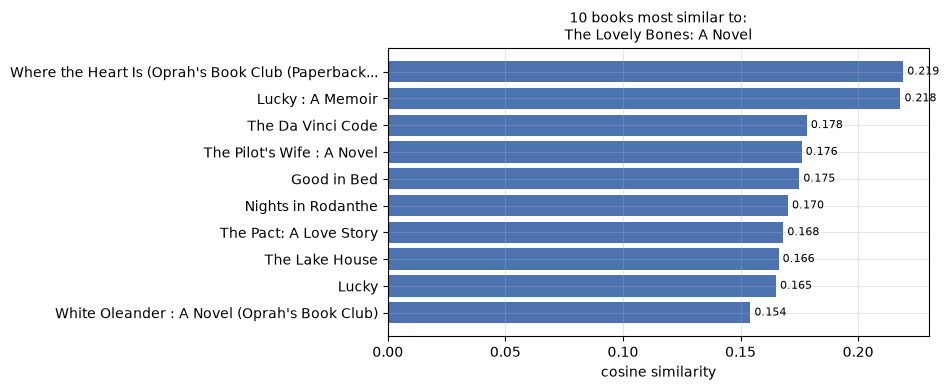

In [50]:
# visual sanity: the similarity profile of one popular book
most_rated_isbn = book_agg.sort_values("n_ratings", ascending=False)["isbn"].iloc[0]
most_rated_title = TITLE[ISBN_TO_COL[most_rated_isbn]]
res, matched, _ = similar_books(most_rated_title, 10)

fig, ax = plt.subplots(figsize=(9.5, 4))
lbl = [t[:48] + ("..." if len(t) > 48 else "") for t in res["title"][::-1]]
ax.barh(lbl, res["similarity"][::-1], color="#4C72B0")
ax.set_xlabel("cosine similarity")
ax.set_title(f"10 books most similar to:\n{matched}", fontsize=10)
for y, v in enumerate(res["similarity"][::-1]):
    ax.text(v, y, f" {v:.3f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

---
# Conclusion

**What was built.** A three-layer medallion lake on disk, then one working item-based
collaborative-filtering recommender on top of its Gold layer.

| Step | Delivered |
|---|---|
| 1 | `bronze/` — three Parquet tables, read with `sep=";"` and Latin-1, all columns text, `ingestion_timestamp` added, nothing cleaned |
| 2 | EDA on the Bronze read-back: shapes, dtypes, missing values, the rating-0 share, impossible ages and years, the per-user/per-book long tail, and a **> 99.99 % sparsity** measurement |
| 3 | `silver/` — de-duplicated, rating 0 dropped, ages repaired by median imputation, `Location` split into city/state/country, bad years nulled, text standardised, image URLs dropped, referential integrity enforced, and an **iterative min-10** filter with the threshold justified from the trade-off table |
| 4 | `gold/` — sparse CSR user×book matrix plus index maps, a book lookup for readable titles, and user/book aggregates |
| 5 | Cosine `NearestNeighbors` on the **books × users** matrix, `similar_books(title)`, and `recommend(user_id, n=10)` scoring by *similarity × the user's own rating*, with read books removed |
| 6 | Three contrasting users demoed side by side with their highly-rated books, plus four falsifiable sanity checks |

**What the pipeline bought us.** Bronze density was about 0.004 % of possible pairs; Gold, after
the min-10 filter, is denser by a large multiple (printed in §3.5). That is the whole point of the
Silver layer — the recommender does not become good by being clever, it becomes good by being
handed co-rating evidence that is thick enough to compute a meaningful cosine on.

**Honest limitations.**

1. **Cold start.** A user or book below the k = 10 threshold is not in Gold at all and cannot be
   served. A production system would fall back to popularity or content features.
2. **Popularity bias.** Item-based CF favours well-rated books, because they share raters with
   more things. Shrinking similarity by co-rating count would damp this.
3. **No offline metric.** The assignment asks for a demo and sanity checks, so correctness here is
   argued structurally (no leakage, valid similarity range, stable ordering) rather than by a
   held-out precision@k. A train/test split on ratings would be the next step.
4. **A 0 is thrown away, not used.** Those rows are genuine *implicit* signal; a hybrid model could
   read them as weak positives instead of discarding them.

---

*Kritika Yadav — LCB2023006 — Data Mining Lab Assignment 2*